# Equivariant PDE Discovery: Allen–Cahn Equation

We study the **Allen–Cahn equation** on $\mathbb{R}^2$:
$$f_t = \varepsilon^2 \Delta f + f - f^3,\qquad \varepsilon=0.15.$$

In [14]:
# standard imports
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
plt.rcParams['figure.figsize'] = (14, 4)

# add parent directory with custom library to path
import sys
sys.path.insert(0, '..')

# simulation tools (ground truth data)
from simulations import allen_cahn, make_regression_data

# library of PDE terms (respects the active derivative backend)
import derivatives
from library import build_equivariant_library, build_standard_library

# regression tools
from regression import TrainSTRidge

# utilities
from utils import print_pde, rotation_90


## 1. Simulate Allen–Cahn via spectral IMEX

The IMEX scheme on the periodic domain $[0, L]^2$:
$$\hat{f}^{n+1} = \frac{\hat{f}^n + \Delta t\,\widehat{(f^n - (f^n)^3)}}{1 + \varepsilon^2 |k|^2 \Delta t}$$

In [15]:
# Simulation parameters
eps        = 0.15        # interface width
N          = 64          # grid points per direction
L          = 2 * np.pi   # domain side length
T_end      = 9.0         # end time (endpoint included)
dt         = 0.01        # time step size for integration (not snapshot frequency)
save_every = 20          # save snapshots every 20 steps  ->  dt_snap = 0.2

snapshots, times = allen_cahn(
    N=N, L=L, T_end=T_end, eps=eps,
    dt=dt, save_every=save_every, seed=42,
)

print(f'Saved {len(snapshots)} snapshots over t ∈ [0, {T_end}]')
print(f'f(t,x) ∈ [{snapshots.min():.3f}, {snapshots.max():.3f}]')

Saved 46 snapshots over t ∈ [0, 9.0]
f(t,x) ∈ [-1.000, 0.999]


/tmp/ipykernel_2534320/514140444.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


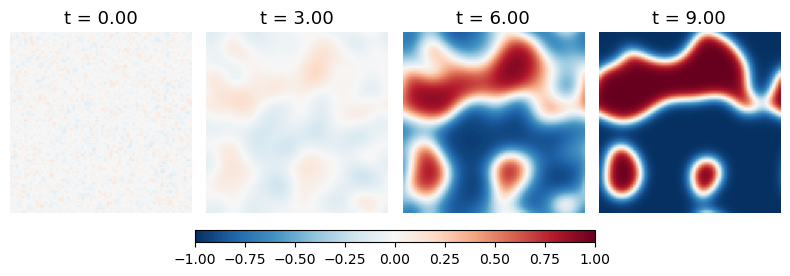

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(8, 3))

pidx = [0, 15, 30, -1]
for ax, idx in zip(axes, pidx):
    im = ax.imshow(snapshots[idx], cmap='RdBu_r', vmin=-1, vmax=1,
                   origin='lower', extent=[0, L, 0, L])
    ax.set_title(f't = {times[idx]:.2f}', fontsize=13)
    ax.axis('off')

# heatbar below subplots
cbar_ax = fig.add_axes([0.25, 0.1, 0.5, 0.04])
fig.colorbar(im, cax=cbar_ax, orientation='horizontal')

plt.tight_layout()
plt.savefig('../../latex/figures/allen_cahn_snapshots.pdf', bbox_inches='tight')

## 2. Extract data for regression

We estimate $f_t$ by central finite difference between consecutive saved snapshots and randomly subsample spatial points.  Both steps are handled by `simulations.make_regression_data()`.

In [17]:
n_per_snap = 200

f_snaps, ft_snaps, idx_sets, dt_snap = make_regression_data(
    snapshots, times, n_per_snap=n_per_snap, seed=0,
)
Ft_all = np.concatenate([ft_snaps[s].ravel()[idx_sets[s]] for s in range(len(f_snaps))])
print(f'{len(f_snaps)} interior snapshots, dt_snap = {dt_snap:.3f}')
print(f'Total regression points: {len(Ft_all)}')

44 interior snapshots, dt_snap = 0.200
Total regression points: 8800


## 3. Libraries of differential terms

We compute the operator values over the full grid for each snapshot, then subsample.

In [18]:
Theta_eq_rows_spec, Theta_std_rows_spec = [], []
Theta_eq_rows_poly, Theta_std_rows_poly = [], []

for s in range(len(f_snaps)):
    fs  = f_snaps[s]
    idx = idx_sets[s]
    with derivatives.use_backend('spectral'):
        Th_eq,  desc_eq  = build_equivariant_library(fs, L, L)
        Th_std, desc_std = build_standard_library(fs, L, L, max_order=4, max_poly=3)
    Theta_eq_rows_spec.append(Th_eq[idx])
    Theta_std_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq,  _ = build_equivariant_library(fs, L, L)
        Th_std, _ = build_standard_library(fs, L, L, max_order=4, max_poly=3)
    Theta_eq_rows_poly.append(Th_eq[idx])
    Theta_std_rows_poly.append(Th_std[idx])

Theta_eq_spec  = np.vstack(Theta_eq_rows_spec).astype(float)
Theta_std_spec = np.vstack(Theta_std_rows_spec).astype(float)
Theta_eq_poly  = np.vstack(Theta_eq_rows_poly).astype(float)
Theta_std_poly = np.vstack(Theta_std_rows_poly).astype(float)

print(f'Library shape : {Theta_eq_spec.shape}')
print(f'Condition numbers (eq / std):')
print(f'  Spectral:   {np.linalg.cond(Theta_eq_spec):.2e} / {np.linalg.cond(Theta_std_spec):.2e}')
print(f'  Polynomial: {np.linalg.cond(Theta_eq_poly):.2e} / {np.linalg.cond(Theta_std_poly):.2e}')


Library shape : (8800, 20)
Condition numbers (eq / std):
  Spectral:   4.68e+03 / 8.35e+03
  Polynomial: 2.05e+03 / 3.49e+03


## 4. Sparse regression (STRidge)

True PDE: $f_t = \varepsilon^2 \Delta f + f - f^3$ with $\varepsilon=0.15$.

Expected non-zero coefficients in equivariant library:

| Term | $f$ | $f^3$ | $\Delta f$ |
|---|---|---|---|
| Coefficient | +1 | -1 | 0.0225 |


In [19]:
lam   = 1e-5
d_tol = 0.05

print('=== Ground truth PDE ===')
print(f'f_t = {eps**2:.4f}*Δf + f - f³\n')

print('── Spectral derivatives ──')
w_eq_spec  = TrainSTRidge(Theta_eq_spec,  Ft_all, lam, d_tol)
w_std_spec = TrainSTRidge(Theta_std_spec, Ft_all, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_spec, desc_eq)
print('Standard:');   print_pde(w_std_spec, desc_std)

print('\n── Polynomial derivatives ──')
w_eq_poly  = TrainSTRidge(Theta_eq_poly,  Ft_all, lam, d_tol)
w_std_poly = TrainSTRidge(Theta_std_poly, Ft_all, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_poly, desc_eq)
print('Standard:');   print_pde(w_std_poly, desc_std)


=== Ground truth PDE ===
f_t = 0.0225*Δf + f - f³

── Spectral derivatives ──
Equivariant:
f_t = (+0.99862)f + (-0.99685)f³ + (+0.02268)Δf
Standard:
f_t = (+0.99859)1 + (+0.02271)f_yy + (+0.02265)f_xx + (-0.99681)f^2

── Polynomial derivatives ──
Equivariant:
f_t = (+1.00596)f + (-0.99484)f³ + (+0.02262)Δf + (-0.02128)f·‖∇f‖²
Standard:
f_t = (+0.98877)1 + (+0.02351)f_yy + (+0.02337)f_xx + (-0.00099)f_xxyy + (-0.98017)f^2


In [20]:
# Summary comparison — define true_eq for reuse in later cells
true_eq = np.zeros(len(desc_eq))
true_eq[1] = 1.0; true_eq[3] = -1.0; true_eq[4] = eps**2
act = np.abs(true_eq) > 1e-10

print('--- Recovery summary (clean data) ---')
print(f'True: f → +1.0, f³ → -1.0, Δf → +{eps**2:.4f}\n')

for tag, w in [('Spectral  eq', w_eq_spec), ('Polynomial eq', w_eq_poly)]:
    nz  = np.count_nonzero(np.abs(w) > 1e-10)
    fp  = int(np.sum((np.abs(w) > 1e-10) & ~act))
    fn  = int(np.sum((np.abs(w) < 1e-10) &  act))
    err = float(np.max(np.abs(w[act] - true_eq[act])))
    print(f'  {tag}: {nz} active, fp={fp}, fn={fn}, max_coeff_err={err:.3e}')

for tag, w in [('Spectral  std', w_std_spec), ('Polynomial std', w_std_poly)]:
    nz = np.count_nonzero(np.abs(w) > 1e-10)
    print(f'  {tag}: {nz} active terms out of {len(w)}')


--- Recovery summary (clean data) ---
True: f → +1.0, f³ → -1.0, Δf → +0.0225

  Spectral  eq: 3 active, fp=0, fn=0, max_coeff_err=3.151e-03
  Polynomial eq: 4 active, fp=1, fn=0, max_coeff_err=5.958e-03
  Spectral  std: 4 active terms out of 60
  Polynomial std: 5 active terms out of 60


## 5. Robustness to noise

We benchmark with added **observation noise**.

In [21]:
noise_level = 0.02   # 2% of clean snapshot std

snapshots_noisy, _ = allen_cahn(
    N=N, L=L, T_end=T_end, eps=eps,
    dt=dt, save_every=save_every, seed=42,
    obs_noise=noise_level,
)

f_snaps_n, ft_snaps_n, idx_sets_n, _ = make_regression_data(
    snapshots_noisy, times, n_per_snap=n_per_snap, seed=0,
)
Ft_n = np.concatenate([ft_snaps_n[s].ravel()[idx_sets_n[s]] for s in range(len(f_snaps_n))])

Theta_eq_n_rows_spec, Theta_std_n_rows_spec = [], []
Theta_eq_n_rows_poly, Theta_std_n_rows_poly = [], []

for s in range(len(f_snaps_n)):
    idx = idx_sets_n[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_n[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_n[s], L, L, max_order=4, max_poly=3)
    Theta_eq_n_rows_spec.append(Th_eq[idx])
    Theta_std_n_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_n[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_n[s], L, L, max_order=4, max_poly=3)
    Theta_eq_n_rows_poly.append(Th_eq[idx])
    Theta_std_n_rows_poly.append(Th_std[idx])

Theta_eq_n_spec  = np.vstack(Theta_eq_n_rows_spec).astype(float)
Theta_std_n_spec = np.vstack(Theta_std_n_rows_spec).astype(float)
Theta_eq_n_poly  = np.vstack(Theta_eq_n_rows_poly).astype(float)
Theta_std_n_poly = np.vstack(Theta_std_n_rows_poly).astype(float)
print(f'Noisy: {len(Ft_n)} regression points, noise={noise_level*100:.0f}%')


Noisy: 8800 regression points, noise=2%


In [22]:
print('=== Ground truth PDE ===')
print(f'f_t = {eps**2:.4f}*Δf + f - f³\n')

print(f'── Spectral (obs_noise = {noise_level*100:.0f}%) ──')
w_eq_n_spec  = TrainSTRidge(Theta_eq_n_spec,  Ft_n, lam, d_tol)
w_std_n_spec = TrainSTRidge(Theta_std_n_spec, Ft_n, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_n_spec, desc_eq)
print('Standard:');   print_pde(w_std_n_spec, desc_std)

print(f'\n── Polynomial (obs_noise = {noise_level*100:.0f}%) ──')
w_eq_n_poly  = TrainSTRidge(Theta_eq_n_poly,  Ft_n, lam, d_tol)
w_std_n_poly = TrainSTRidge(Theta_std_n_poly, Ft_n, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_n_poly, desc_eq)
print('Standard:');   print_pde(w_std_n_poly, desc_std)

print('\n--- Noisy recovery summary ---')
for tag, w in [('Spectral  eq', w_eq_n_spec), ('Polynomial eq', w_eq_n_poly)]:
    fp  = int(np.sum((np.abs(w) > 1e-10) & ~act))
    fn  = int(np.sum((np.abs(w) < 1e-10) &  act))
    err = float(np.max(np.abs(w[act] - true_eq[act])))
    print(f'  {tag}: fp={fp}, fn={fn}, max_coeff_err={err:.3e}')


=== Ground truth PDE ===
f_t = 0.0225*Δf + f - f³

── Spectral (obs_noise = 2%) ──
Equivariant:
f_t = (+0.90400)f + (-0.91037)f³ + (+0.00834)Δf + (-0.04336)f·‖∇f‖² + (+0.00001)Δ²f + (+0.00053)‖∇f‖²·Δf + (-0.00083)∇²f(∇f,∇f)
Standard:
f_t = (+0.87127)1 + (+0.01525)f_yy + (+0.01463)f_xx + (+0.00002)f_yyyy + (+0.00002)f_xxxx + (-0.86864)f^2

── Polynomial (obs_noise = 2%) ──
Equivariant:
f_t = (+0.99155)f + (-0.97926)f³ + (+0.02173)Δf + (-0.02169)f·‖∇f‖²
Standard:
f_t = (+0.97166)1 + (+0.02594)f_yy + (+0.02587)f_xx + (-0.95037)f^2

--- Noisy recovery summary ---
  Spectral  eq: fp=4, fn=0, max_coeff_err=9.600e-02
  Polynomial eq: fp=1, fn=0, max_coeff_err=2.074e-02


## 6. Equivariance test

We rotate the data by 90° and repeat the regression.

In [23]:
# Rotate all snapshots 90° and re-run the same pipeline
snaps_r = rotation_90(snapshots.transpose(1, 2, 0)).transpose(2, 0, 1)

f_snaps_r, ft_snaps_r, idx_sets_r, _ = make_regression_data(
    snaps_r, times, n_per_snap=n_per_snap, seed=0,
)
Ft_r = np.concatenate([ft_snaps_r[s].ravel()[idx_sets_r[s]] for s in range(len(f_snaps_r))])

Theta_eq_r_rows_spec, Theta_std_r_rows_spec = [], []
Theta_eq_r_rows_poly, Theta_std_r_rows_poly = [], []

for s in range(len(f_snaps_r)):
    idx = idx_sets_r[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_r[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_r[s], L, L, max_order=4, max_poly=3)
    Theta_eq_r_rows_spec.append(Th_eq[idx])
    Theta_std_r_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_r[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_r[s], L, L, max_order=4, max_poly=3)
    Theta_eq_r_rows_poly.append(Th_eq[idx])
    Theta_std_r_rows_poly.append(Th_std[idx])

Theta_eq_r_spec  = np.vstack(Theta_eq_r_rows_spec).astype(float)
Theta_std_r_spec = np.vstack(Theta_std_r_rows_spec).astype(float)
Theta_eq_r_poly  = np.vstack(Theta_eq_r_rows_poly).astype(float)
Theta_std_r_poly = np.vstack(Theta_std_r_rows_poly).astype(float)

print('── Spectral (rotated clean) ──')
w_eq_r_spec  = TrainSTRidge(Theta_eq_r_spec,  Ft_r, lam, d_tol)
w_std_r_spec = TrainSTRidge(Theta_std_r_spec, Ft_r, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_r_spec, desc_eq)
print('Standard:');   print_pde(w_std_r_spec, desc_std)

print('\n── Polynomial (rotated clean) ──')
w_eq_r_poly  = TrainSTRidge(Theta_eq_r_poly,  Ft_r, lam, d_tol)
w_std_r_poly = TrainSTRidge(Theta_std_r_poly, Ft_r, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_r_poly, desc_eq)
print('Standard:');   print_pde(w_std_r_poly, desc_std)


── Spectral (rotated clean) ──
Equivariant:
f_t = (+0.99706)f + (-0.99543)f³ + (+0.02256)Δf
Standard:
f_t = (+0.99708)1 + (+0.02258)f_yy + (+0.02252)f_xx + (-0.99544)f^2

── Polynomial (rotated clean) ──
Equivariant:
f_t = (+0.98987)f + (-0.97002)f³ + (+0.02676)Δf
Standard:
f_t = (+0.99022)1 + (+0.02716)f_yy + (+0.02634)f_xx + (-0.97032)f^2


In [24]:
print('Coefficient change under 90° rotation (clean data):')
for tag, w, wr in [
    ('Spectral  eq',  w_eq_spec,  w_eq_r_spec),
    ('Polynomial eq', w_eq_poly,  w_eq_r_poly),
    ('Spectral  std', w_std_spec, w_std_r_spec),
    ('Polynomial std',w_std_poly, w_std_r_poly),
]:
    print(f'  {tag}: max|Δc| = {np.max(np.abs(w - wr)):.2e}')


Coefficient change under 90° rotation (clean data):
  Spectral  eq: max|Δc| = 1.56e-03
  Polynomial eq: max|Δc| = 2.48e-02
  Spectral  std: max|Δc| = 1.51e-03
  Polynomial std: max|Δc| = 9.85e-03


In [25]:
snaps_noisy_r = rotation_90(snapshots_noisy.transpose(1, 2, 0)).transpose(2, 0, 1)

f_snaps_rn, ft_snaps_rn, idx_sets_rn, _ = make_regression_data(
    snaps_noisy_r, times, n_per_snap=n_per_snap, seed=0,
)
Ft_rn = np.concatenate([ft_snaps_rn[s].ravel()[idx_sets_rn[s]] for s in range(len(f_snaps_rn))])

Theta_eq_rn_rows_spec, Theta_std_rn_rows_spec = [], []
Theta_eq_rn_rows_poly, Theta_std_rn_rows_poly = [], []

for s in range(len(f_snaps_rn)):
    idx = idx_sets_rn[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_rn[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_rn[s], L, L, max_order=4, max_poly=3)
    Theta_eq_rn_rows_spec.append(Th_eq[idx])
    Theta_std_rn_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_rn[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_rn[s], L, L, max_order=4, max_poly=3)
    Theta_eq_rn_rows_poly.append(Th_eq[idx])
    Theta_std_rn_rows_poly.append(Th_std[idx])

Theta_eq_rn_spec  = np.vstack(Theta_eq_rn_rows_spec).astype(float)
Theta_std_rn_spec = np.vstack(Theta_std_rn_rows_spec).astype(float)
Theta_eq_rn_poly  = np.vstack(Theta_eq_rn_rows_poly).astype(float)
Theta_std_rn_poly = np.vstack(Theta_std_rn_rows_poly).astype(float)

print('── Spectral (noisy + rotated) ──')
w_eq_rn_spec  = TrainSTRidge(Theta_eq_rn_spec,  Ft_rn, lam, d_tol)
w_std_rn_spec = TrainSTRidge(Theta_std_rn_spec, Ft_rn, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_rn_spec, desc_eq)
print('Standard:');   print_pde(w_std_rn_spec, desc_std)

print('\n── Polynomial (noisy + rotated) ──')
w_eq_rn_poly  = TrainSTRidge(Theta_eq_rn_poly,  Ft_rn, lam, d_tol)
w_std_rn_poly = TrainSTRidge(Theta_std_rn_poly, Ft_rn, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_rn_poly, desc_eq)
print('Standard:');   print_pde(w_std_rn_poly, desc_std)


── Spectral (noisy + rotated) ──
Equivariant:
f_t = (+0.90770)f + (-0.91823)f³ + (+0.00819)Δf + (-0.04470)f·‖∇f‖² + (+0.00001)Δ²f + (+0.00058)‖∇f‖²·Δf + (-0.00089)∇²f(∇f,∇f)
Standard:
f_t = (+0.88356)1 + (+0.01547)f_yy + (+0.01479)f_xx + (+0.00002)f_yyyy + (+0.00002)f_xxxx + (-0.88477)f^2

── Polynomial (noisy + rotated) ──
Equivariant:
f_t = (+0.99947)f + (-0.98890)f³ + (+0.02236)Δf + (-0.02122)f·‖∇f‖²
Standard:
f_t = (+0.98116)1 + (+0.02664)f_yy + (+0.02601)f_xx + (-0.96192)f^2


In [26]:
print('Coefficient change under 90° rotation (noisy data):')
for tag, w, wr in [
    ('Spectral  eq',  w_eq_n_spec,  w_eq_rn_spec),
    ('Polynomial eq', w_eq_n_poly,  w_eq_rn_poly),
    ('Spectral  std', w_std_n_spec, w_std_rn_spec),
    ('Polynomial std',w_std_n_poly, w_std_rn_poly),
]:
    print(f'  {tag}: max|Δc| = {np.max(np.abs(w - wr)):.2e}')


Coefficient change under 90° rotation (noisy data):
  Spectral  eq: max|Δc| = 7.86e-03
  Polynomial eq: max|Δc| = 9.63e-03
  Spectral  std: max|Δc| = 1.61e-02
  Polynomial std: max|Δc| = 1.16e-02
